# From Pixels to Predictions
**CSI 5550 - Visual Computing**

Implement sampling, quantization, affine rotation, and histogram equalization.
Then measure how **your implementations** affect a trained image classifier.

**Instructor copy: includes completed implementations.**

## 1. Setup
We use ResNet-18, already trained on ImageNet, with weights supplied by
[TorchVision](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html).
No training is needed. We restrict its predictions to the ten Imagenette categories.
Images are resized/cropped to 224×224 before your operators; model normalization happens afterward.

In [1]:
import math
import os
import sys
from importlib import reload
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from IPython.display import display
from torch.utils.data import DataLoader

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/cnn_signal_sensitivity").exists())
sys.path.insert(0, str(ROOT / "src"))
os.environ["TORCH_HOME"] = str(ROOT / "data/models")

from cnn_signal_sensitivity import checks, experiments
from cnn_signal_sensitivity.data import CachedInputs, case_studies, load_lab_data
from cnn_signal_sensitivity.evaluation import predict, run_suite, seed_everything
from cnn_signal_sensitivity.models import choose_device, load_classifier
from cnn_signal_sensitivity.plotting import (
    image_grid,
    plot_curves,
    transformation_gallery,
)
from cnn_signal_sensitivity.transforms import identity_condition

reload(checks)  # refresh checks if this kernel imported an older version
seed_everything(5550)
torch.set_num_threads(min(8, os.cpu_count() or 1))
DEVICE = choose_device()
OUTPUT = ROOT / "outputs/lab"
OUTPUT.mkdir(parents=True, exist_ok=True)
print(f"Using {DEVICE}")

Using cuda


## 2. Original images and predictions
We use the same 200 images for every comparison. Accuracy is the percentage classified
correctly; confidence is the model's probability among the ten possible categories.

Original-image accuracy: 99.5%


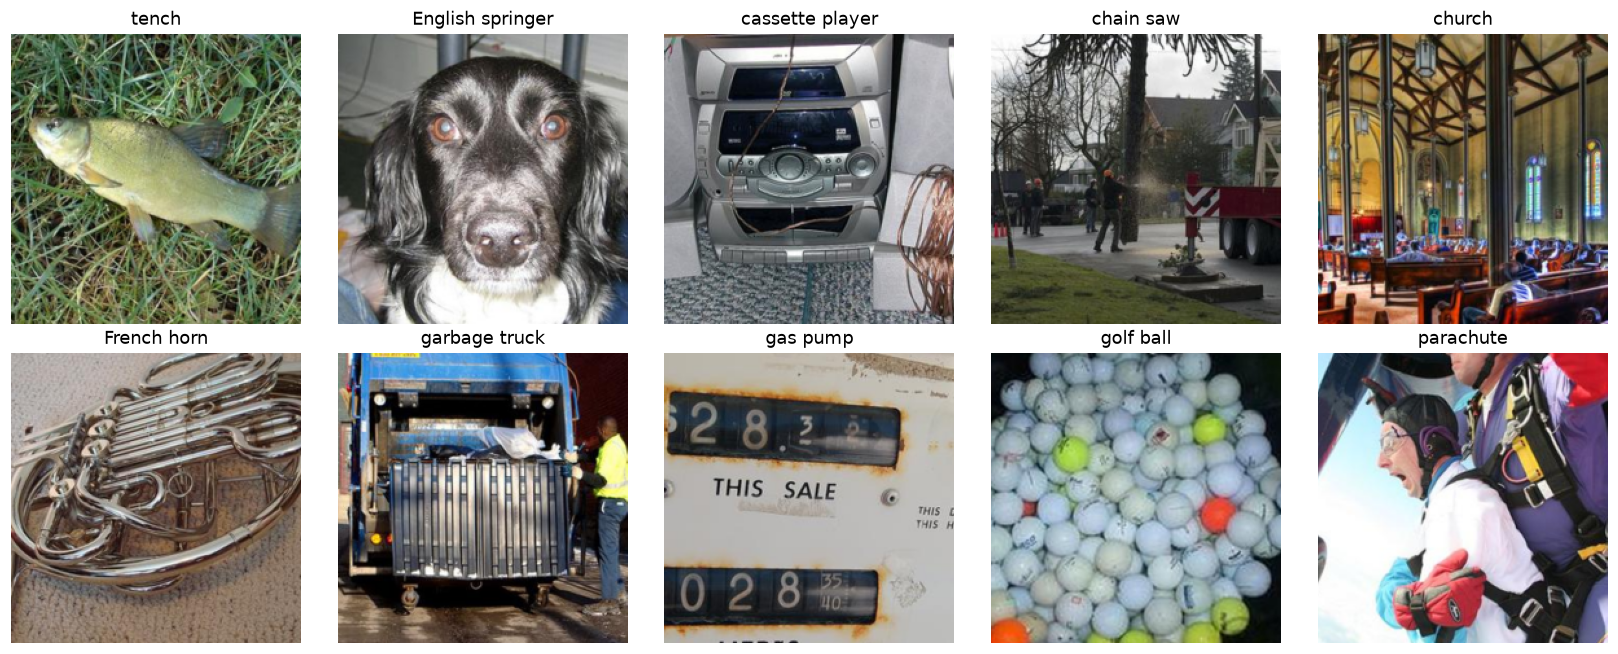

In [2]:
dataset = CachedInputs(load_lab_data(ROOT / "data"))
loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)
model = load_classifier(DEVICE)
clean = predict(model, loader, identity_condition())
print(f"Original-image accuracy: {100 * clean.correct.mean():.1f}%")
case_images, case_labels, case_ids = case_studies(dataset)
fig = image_grid(case_images, case_labels)
plt.show()

The four operations are:

| Operation | What changes in the image |
|---|---|
| Sampling and interpolation | Reduce spatial samples, then reconstruct. |
| Intensity quantization | Use fewer intensity levels. |
| Affine rotation | Rotate and interpolate pixel values. |
| Histogram equalization | Redistribute grayscale intensities to change contrast. |

**Before running:** Which of the four operations should change predictions most? Why?

**Your prediction:** TODO

## 3. Implement the operators
Inputs are floating-point RGB tensors of shape (B,3,H,W), with values in [0,1].
Preserve shape, dtype, and device; do not change the input in place.

### A. Image sampling and interpolation
Sampling determines how finely an image's spatial detail is represented.
Keep every factor-th row and column. Reconstruct the original size using
nearest-neighbor interpolation: repeat samples, then crop to the original dimensions.
Factor 1 should reproduce the input. Use slicing and tensor repetition.

In [3]:
def sample_image(images: torch.Tensor, factor: int) -> torch.Tensor:
    """Reduce spatial sampling, then reconstruct using nearest neighbors.

    Args:
        images: Float RGB batch in [0, 1], shaped (B, 3, H, W).
            B is the number of images; H and W are height and width.
        factor: Positive integer spacing between retained rows and columns.

    Returns:
        Reconstructed batch with the same shape, dtype, and device as images.
        The input is not modified.
    """
    if not isinstance(factor, int) or factor < 1:
        raise ValueError("factor must be a positive integer.")
    height, width = images.shape[-2:]
    sampled = images[:, :, ::factor, ::factor]
    return sampled.repeat_interleave(factor, -2).repeat_interleave(factor, -1)[
        :, :, :height, :width
    ]

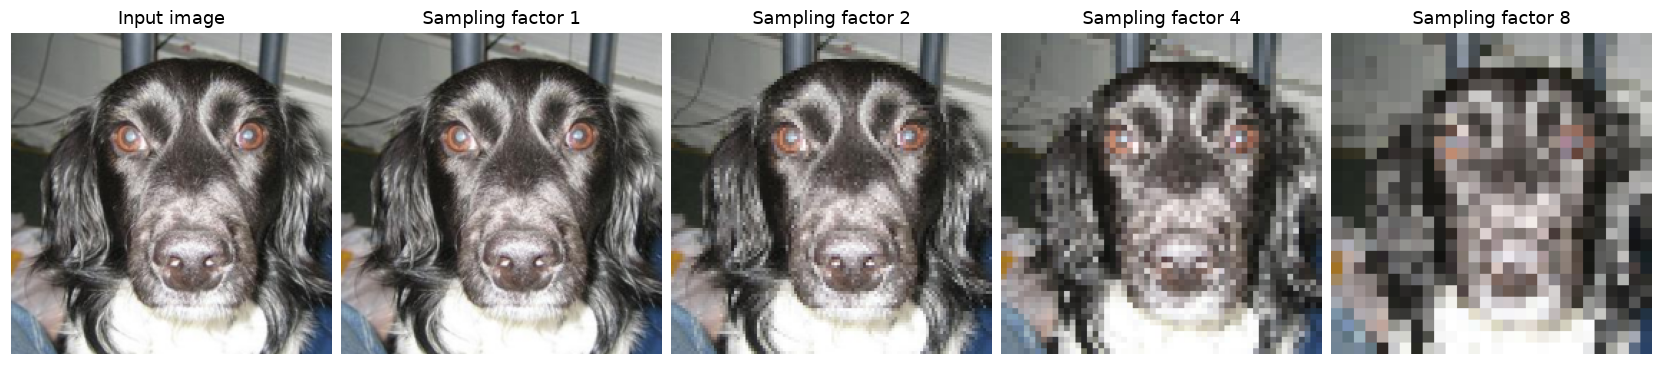

In [4]:
demo_input = case_images[1:2].clone()
factors = [1, 2, 4, 8]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), layout="constrained")
axes[0].imshow(demo_input[0].permute(1, 2, 0).cpu())
axes[0].set_title("Input image")
for ax, factor in zip(axes[1:], factors):
    sampled = sample_image(demo_input, factor=factor)
    ax.imshow(sampled[0].permute(1, 2, 0).cpu())
    ax.set_title(f"Sampling factor {factor}")
for ax in axes:
    ax.axis("off")
fig.savefig(OUTPUT / "demo_sample_image.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
checks.check_sampling(sample_image)

Sampling checks passed.


### B. Intensity quantization
Quantization represents pixel intensities using a finite number of levels.
Implement $Q_b(x)=\mathrm{round}[(2^b-1)x]/(2^b-1)$ for integer $1\leq b\leq8$.
Eight bits preserves the original 8-bit samples. Lower bit depths retain fewer intensity levels.

In [6]:
def quantize(images: torch.Tensor, bits: int) -> torch.Tensor:
    """Reduce intensity resolution to 2**bits uniformly spaced levels in [0, 1].

    Args:
        images: Float RGB batch in [0, 1], shaped (B, 3, H, W).
            B is the number of images; H and W are height and width.
        bits: Integer bit depth from 1 to 8, applied to each color channel.

    Returns:
        Quantized batch with the same shape, dtype, and device as images.
        The input is not modified.
    """
    if not isinstance(bits, int) or not 1 <= bits <= 8:
        raise ValueError("bits must be an integer in [1, 8].")
    levels = 2**bits - 1
    return torch.round(images * levels) / levels

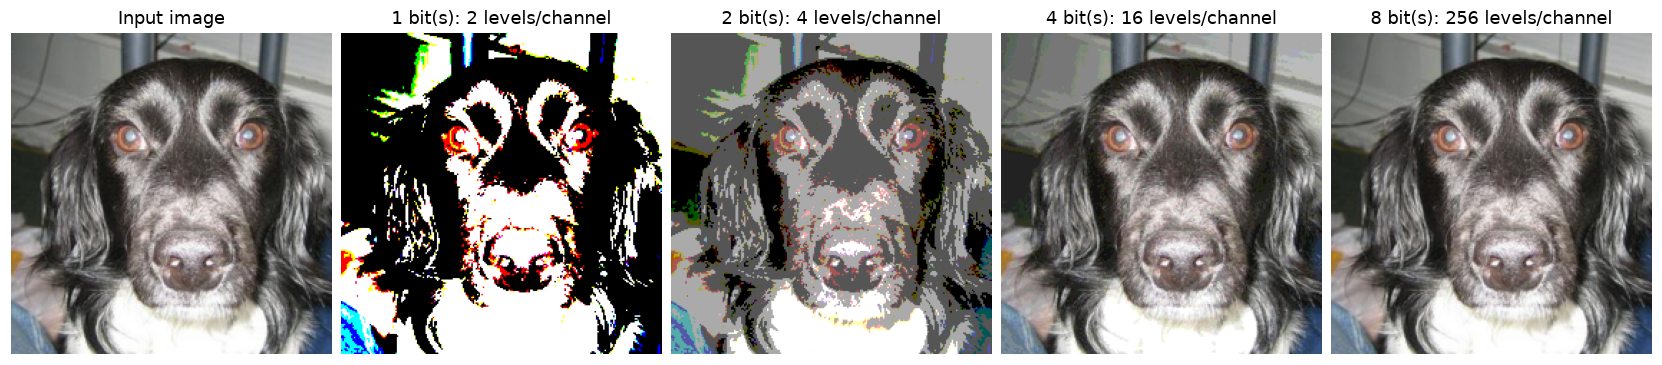

In [7]:
demo_input = case_images[1:2].clone()
bit_depths = [1, 2, 4, 8]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), layout="constrained")
axes[0].imshow(demo_input[0].permute(1, 2, 0).cpu())
axes[0].set_title("Input image")
for ax, bits in zip(axes[1:], bit_depths):
    quantized = quantize(demo_input, bits=bits)
    ax.imshow(quantized[0].permute(1, 2, 0).cpu())
    ax.set_title(f"{bits} bit(s): {2**bits} levels/channel")
for ax in axes:
    ax.axis("off")
fig.savefig(OUTPUT / "demo_quantize.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
checks.check_quantize(quantize)

Quantization checks passed.


### C. Affine geometric transformation
A geometric transformation changes pixel locations; interpolation assigns their intensities.
Rotate about the image center using inverse coordinate mapping and bilinear interpolation.
Positive angles are counterclockwise degrees. Keep the original canvas and fill outside
regions with 0.5. Construct the coordinate grid yourself; grid_sample is allowed.
See ASSIGNMENT.md for coordinate conventions.

In [9]:
def affine_rotation(images: torch.Tensor, angle: float) -> torch.Tensor:
    """Rotate around the center using inverse mapping and bilinear interpolation.

    Args:
        images: Float RGB batch in [0, 1], shaped (B, 3, H, W).
            B is the number of images; H and W are height and width.
        angle: Counterclockwise rotation in degrees, applied to every image.

    Returns:
        Rotated batch with the same shape, dtype, and device as images.
        Outside regions use gray (0.5). The input is not modified.
    """
    if not math.isfinite(angle):
        raise ValueError("angle must be finite.")
    if angle == 0:
        return images.clone()
    batch, _, height, width = images.shape
    y, x = torch.meshgrid(
        torch.arange(height, device=images.device, dtype=images.dtype),
        torch.arange(width, device=images.device, dtype=images.dtype),
        indexing="ij",
    )
    x, y = x - (width - 1) / 2, y - (height - 1) / 2
    radians = math.radians(angle)
    cosine, sine = math.cos(radians), math.sin(radians)
    source_x = cosine * x - sine * y + (width - 1) / 2
    source_y = sine * x + cosine * y + (height - 1) / 2
    grid = torch.stack(
        (2 * (source_x + 0.5) / width - 1, 2 * (source_y + 0.5) / height - 1), dim=-1
    )
    grid = grid.unsqueeze(0).expand(batch, -1, -1, -1)
    return (
        F.grid_sample(
            images - 0.5, grid, mode="bilinear", padding_mode="zeros", align_corners=False
        )
        + 0.5
    ).clamp(0, 1)

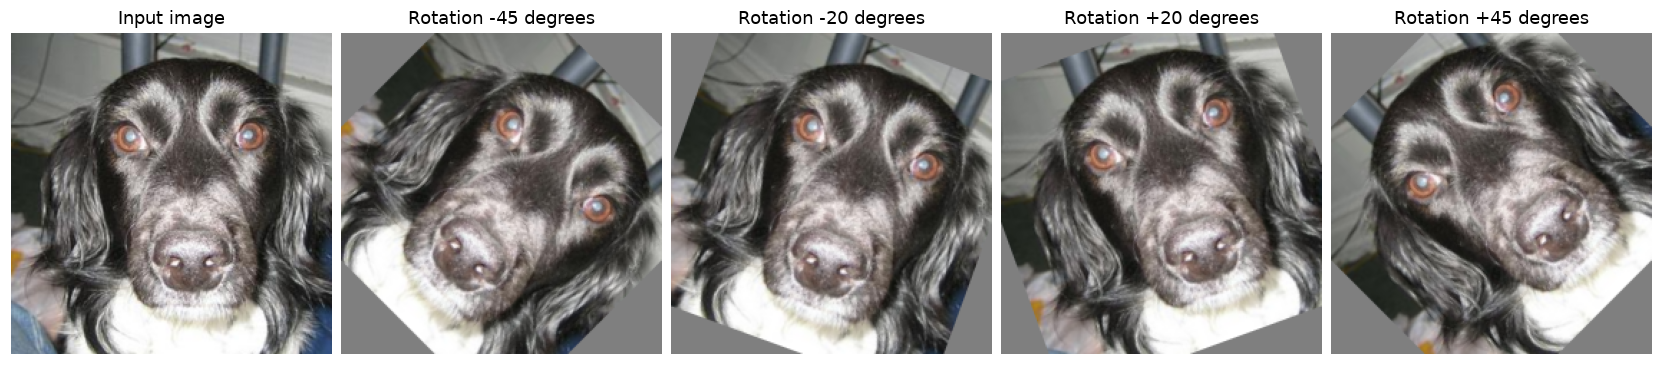

In [10]:
demo_input = case_images[1:2].clone()
angles = [-45, -20, 20, 45]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), layout="constrained")
axes[0].imshow(demo_input[0].permute(1, 2, 0).cpu())
axes[0].set_title("Input image")
for ax, angle in zip(axes[1:], angles):
    rotated = affine_rotation(demo_input, angle=angle)
    ax.imshow(rotated[0].permute(1, 2, 0).cpu())
    ax.set_title(f"Rotation {angle:+d} degrees")
for ax in axes:
    ax.axis("off")
fig.savefig(OUTPUT / "demo_affine_rotation.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
checks.check_affine(affine_rotation)

Affine rotation checks passed.


### D1. Image histogram
A histogram counts how many pixels have each intensity level.
First convert RGB to grayscale using the channel mean, then round intensity*255 into 256 bins.
Return a separate row of counts for each image; do not combine the batch.
Use this function to plot the histograms before and after equalization.

In [12]:
def image_histogram(images: torch.Tensor) -> torch.Tensor:
    """Count pixels at each of 256 intensity levels, separately for every image.

    Args:
        images: Float RGB batch in [0, 1], shaped (B, 3, H, W).
            B is the number of images; H and W are height and width.

    Returns:
        Integer pixel counts shaped (B, 256), on the input device.
        Use the RGB channel mean as intensity and round intensity*255
        to select bins 0 through 255. Each histogram sums to H*W.
        The input is not modified.
    """
    bins = torch.round(images.mean(dim=1) * 255).long()
    return torch.stack([torch.bincount(image.flatten(), minlength=256) for image in bins])

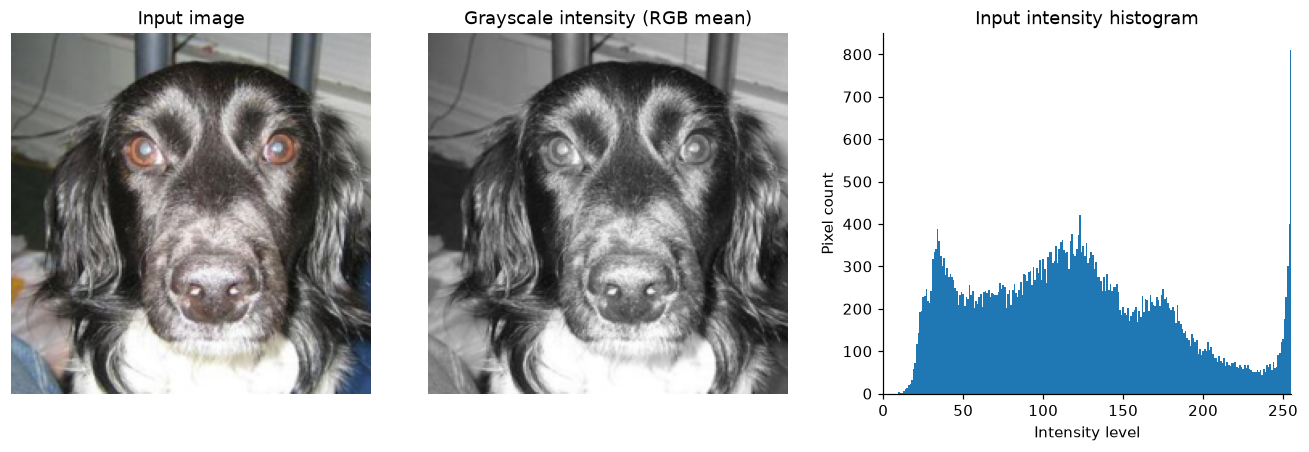

In [13]:
histogram_input = case_images[1:2].clone()
grayscale_input = histogram_input.mean(dim=1, keepdim=True)
counts = image_histogram(histogram_input)[0]
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
axes[0].imshow(histogram_input[0].permute(1, 2, 0).cpu())
axes[0].set_title("Input image")
axes[0].axis("off")
axes[1].imshow(grayscale_input[0, 0].cpu(), cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Grayscale intensity (RGB mean)")
axes[1].axis("off")
axes[2].bar(range(256), counts.cpu().numpy(), width=1)
axes[2].set(title="Input intensity histogram", xlabel="Intensity level", ylabel="Pixel count", xlim=(0, 255))
fig.savefig(OUTPUT / "demo_image_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
checks.check_image_histogram(image_histogram)

Image histogram checks passed.


### D2. Histogram equalization
Histogram equalization redistributes intensity levels to spread contrast across their range.
Convert RGB to intensity using its channel mean. For each image, compute a 256-bin
histogram and cumulative distribution. Map intensities using (CDF−CDF_min)/(1−CDF_min).
Compute the histogram inside this function, independently of image_histogram.
Leave constant-intensity images unchanged. Replicate the result into three channels.

In [15]:
def histogram_equalize(images: torch.Tensor) -> torch.Tensor:
    """Redistribute grayscale intensities using each image's cumulative histogram.

    Args:
        images: Float RGB batch in [0, 1], shaped (B, 3, H, W).
            B is the number of images; H and W are height and width.

    Returns:
        Equalized grayscale batch in [0, 1], with intensity replicated across
        three channels. Shape, dtype, and device match images. Each image is
        equalized independently, and the input is not modified.
    """
    gray = images.mean(dim=1, keepdim=True)
    output = []
    for image in gray:
        bins = torch.round(image * 255).long()
        histogram = torch.bincount(bins.flatten(), minlength=256).to(images.dtype)
        cdf = histogram.cumsum(0)
        minimum = cdf[histogram > 0][0]
        denominator = cdf[-1] - minimum
        if denominator == 0:
            output.append(image.clone())
        else:
            mapping = ((cdf - minimum) / denominator).clamp(0, 1)
            output.append(mapping[bins])
    return torch.stack(output).expand(-1, 3, -1, -1).contiguous()

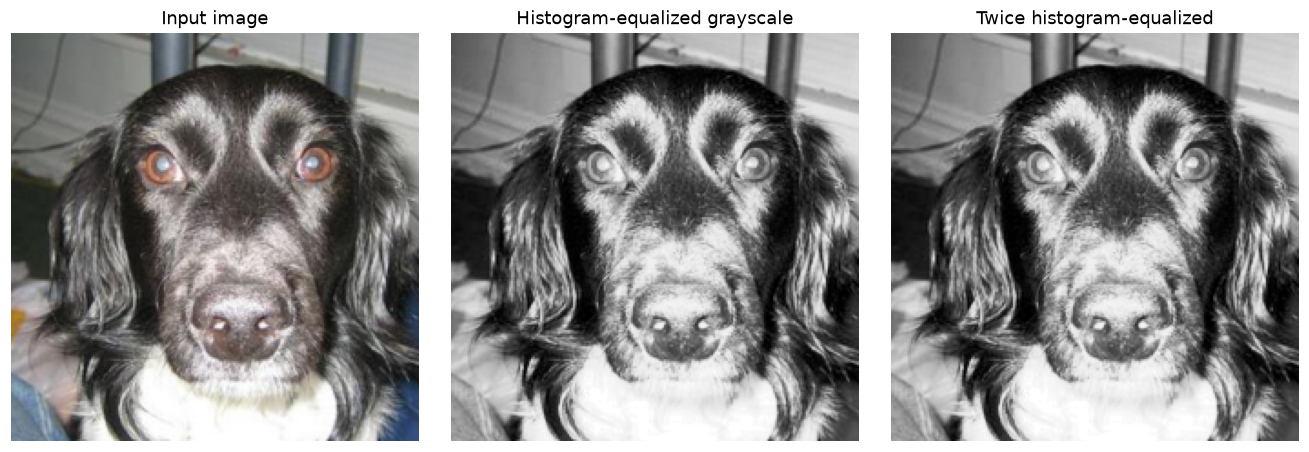

In [16]:
demo_input = case_images[1:2].clone()
demo_output = histogram_equalize(demo_input)
twice_equalized = histogram_equalize(demo_output)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, image, title in zip(axes, [demo_input, demo_output, twice_equalized],
                           ["Input image", "Histogram-equalized grayscale", "Twice histogram-equalized"]):
    ax.imshow(image[0].permute(1, 2, 0).cpu())
    ax.set_title(title)
    ax.axis("off")
fig.savefig(OUTPUT / "demo_histogram_equalize.png", dpi=150, bbox_inches="tight")
plt.show()

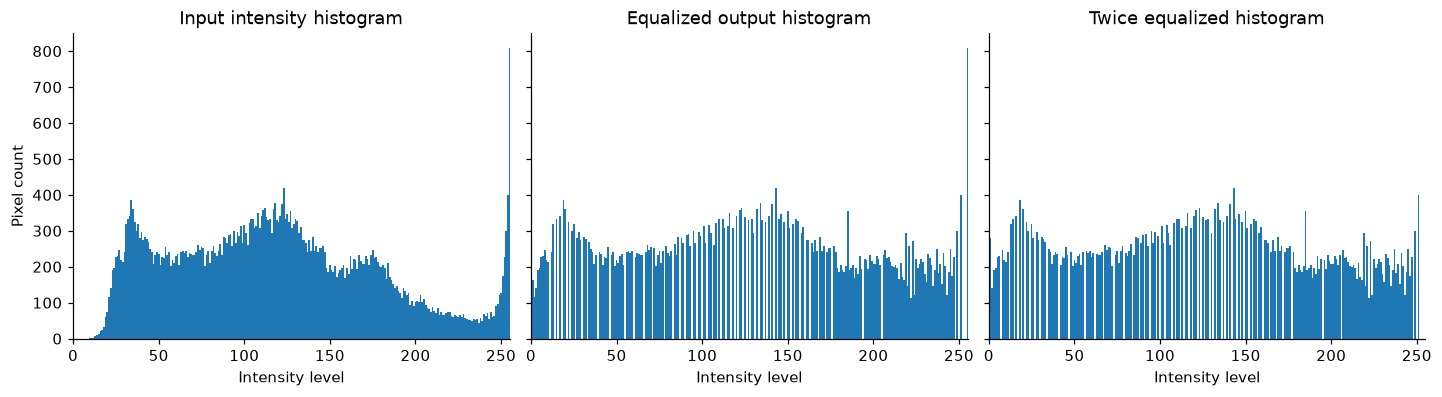

In [17]:
input_counts = image_histogram(demo_input)[0]
output_counts = image_histogram(demo_output)[0]
twice_counts = image_histogram(twice_equalized)[0]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True, sharey=True, layout="constrained")
for ax, counts, title in zip(axes, [input_counts, output_counts, twice_counts],
                            ["Input intensity histogram", "Equalized output histogram", "Twice equalized histogram"]):
    ax.bar(range(256), counts.cpu().numpy(), width=1)
    ax.set(title=title, xlabel="Intensity level", xlim=(0, 255))
axes[0].set_ylabel("Pixel count")
fig.savefig(OUTPUT / "histogram_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
checks.check_histogram(histogram_equalize)

Histogram equalization checks passed.


## 4. Compare your results
The evaluation below calls the four functions you just wrote.
The grayscale comparison isolates histogram equalization from the removal of color.
Rotation can also crop objects; inspect the images before interpreting accuracy changes.

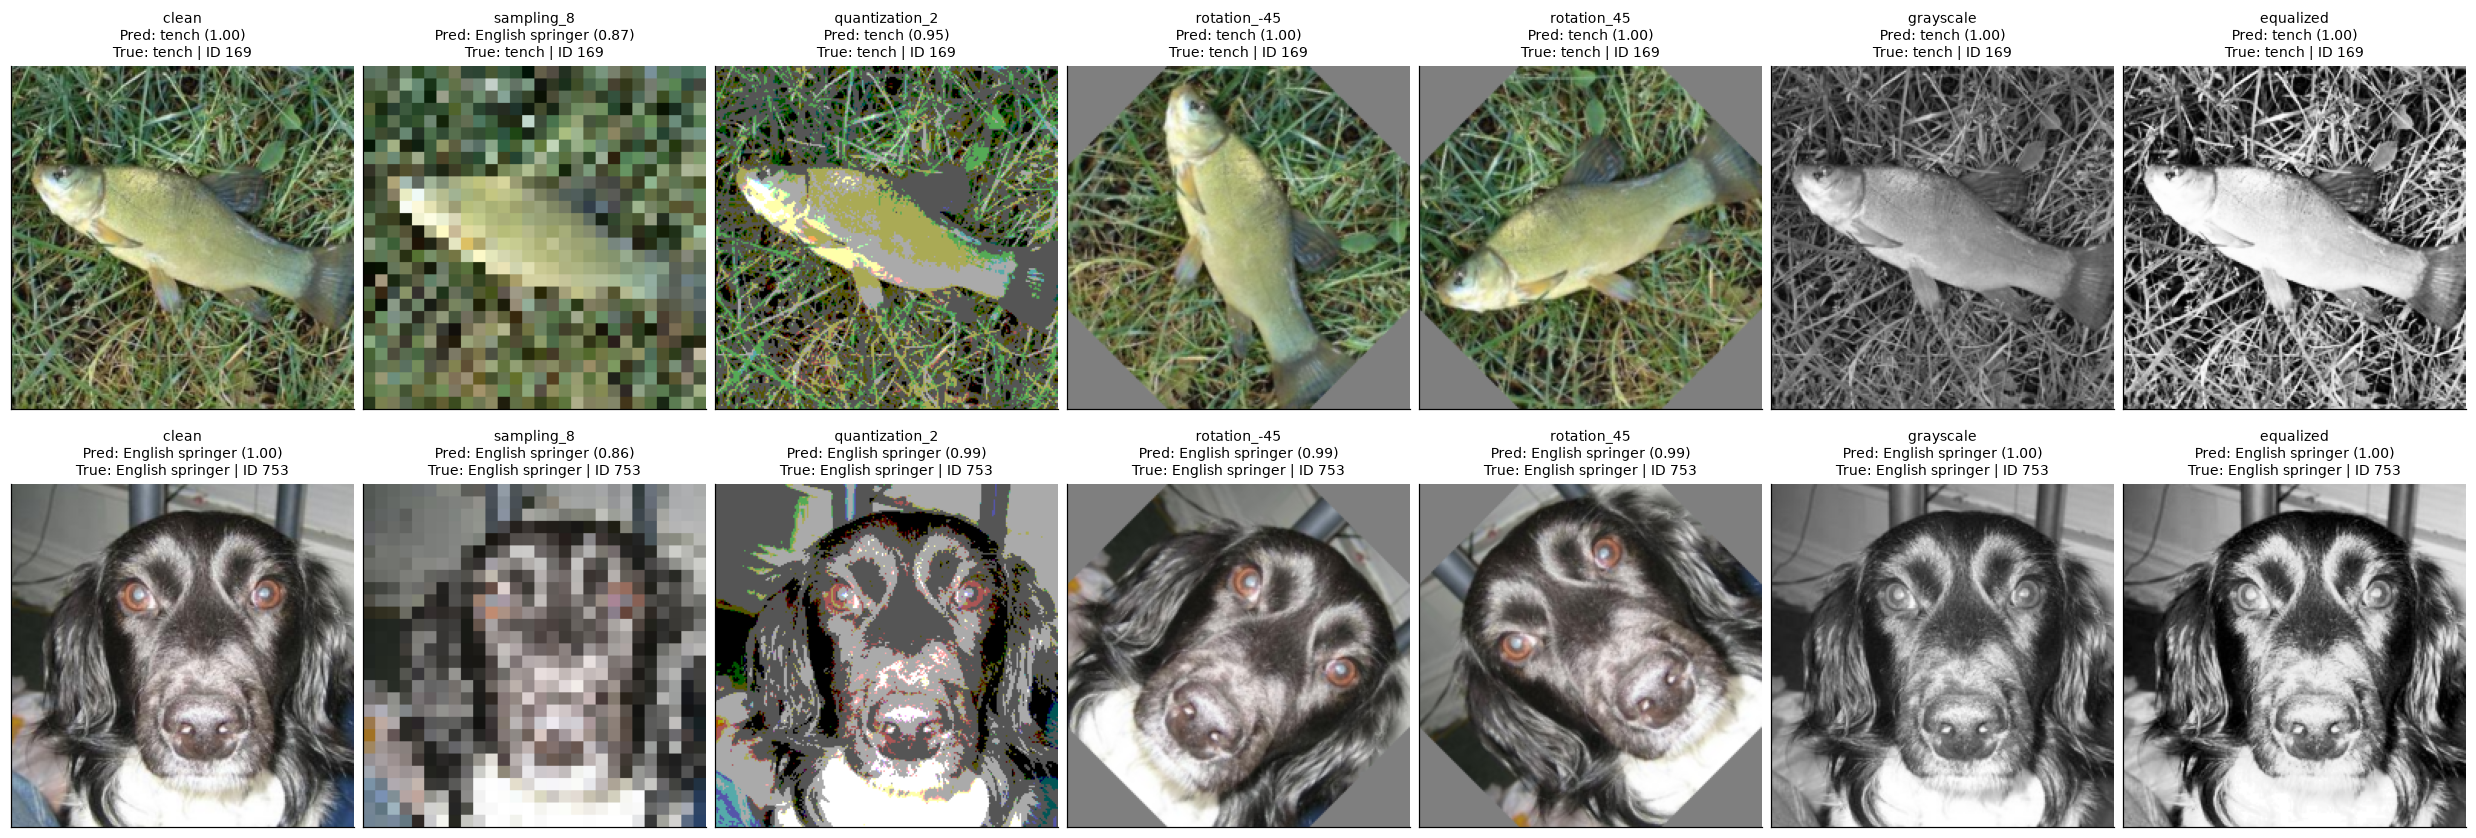

In [19]:
reload(experiments)  # pick up updated rotation settings in an existing kernel
conditions = experiments.lab_conditions(sample_image, quantize, affine_rotation, histogram_equalize)
selected = [c for c in conditions if c.key in
            {'clean', 'sampling_8', 'quantization_2', 'rotation_-45', 'rotation_45', 'grayscale', 'equalized'}]
fig = transformation_gallery(model, case_images[:2], case_labels[:2], case_ids[:2], selected)
fig.savefig(OUTPUT / "examples.png", dpi=150, bbox_inches="tight")
plt.show()

[1/20] clean: 99.50%


[2/20] sampling_1: 99.50%


[3/20] sampling_2: 98.50%


[4/20] sampling_4: 75.00%


[5/20] sampling_8: 35.00%


[6/20] sampling_16: 19.00%


... (11 outputs left out)

[18/20] rotation_45: 84.00%


[19/20] grayscale: 99.00%


[20/20] equalized: 98.00%


,condition,accuracy_pct,drop_pp,flip_pct
0,clean,99.5,0.0,0.0
1,sampling_1,99.5,0.0,0.0
2,sampling_2,98.5,1.0,1.5
3,sampling_4,75.0,24.5,25.0
4,sampling_8,35.0,64.5,65.0
5,sampling_16,19.0,80.5,81.0
6,quantization_8,99.5,0.0,0.0
7,quantization_6,99.5,0.0,0.0
8,quantization_4,99.0,0.5,0.5
9,quantization_3,98.5,1.0,1.5


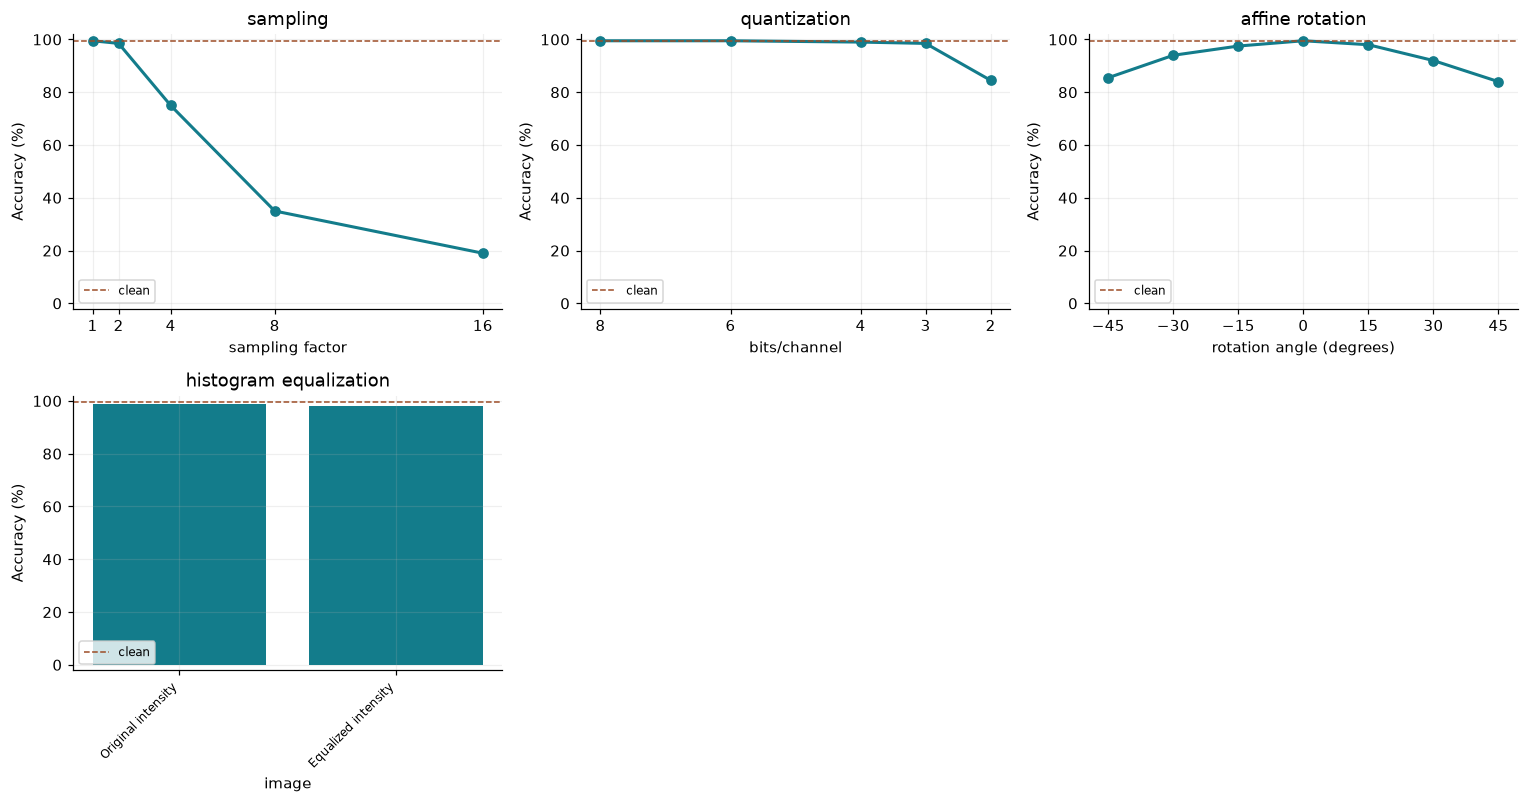

In [20]:
table, results = run_suite(model, loader, conditions, OUTPUT, baseline=clean,
                           metadata={"subset_manifest": "data/lab_subset.json"})
display(table[['condition', 'accuracy_pct', 'drop_pp', 'flip_pct']].round(2))
fig = plot_curves(table)
fig.savefig(OUTPUT / "accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

Accuracy drop is measured in percentage points from the original images.
Prediction flips can introduce errors or correct them.

**Discuss:** Did your results match your prediction? Explain the effects of sampling,
intensity resolution, interpolation, and contrast. Did histogram equalization help
compared with grayscale? Support your answers with numbers and examples.

**Your discussion:** TODO